Input VALUES:
 tensor([[-1.1258, -1.1524, -0.2506, -0.4339,  0.8487,  0.6920],
        [-0.3160, -2.1152,  0.4681, -0.1577,  1.4437,  0.2660],
        [ 0.1665,  0.8744, -0.1435, -0.1116,  0.9318,  1.2590],
        [ 2.0050,  0.0537,  0.6181, -0.4128, -0.8411, -2.3160]])

>>> Tracking TOKEN 1, DIM 2 (marked as 1 below)

tensor([[0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.]])

Q MASK (per head):
 tensor([[[0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 1.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.]]])
K MASK (per head):
 tensor([[[0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 1.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 0.],
         [0., 0., 0.]]])
V MASK (per head):
 tensor([[[0., 0., 0.],
         [0., 0., 0.]],

        [[0., 0., 1.],
         [0., 0., 0.]],



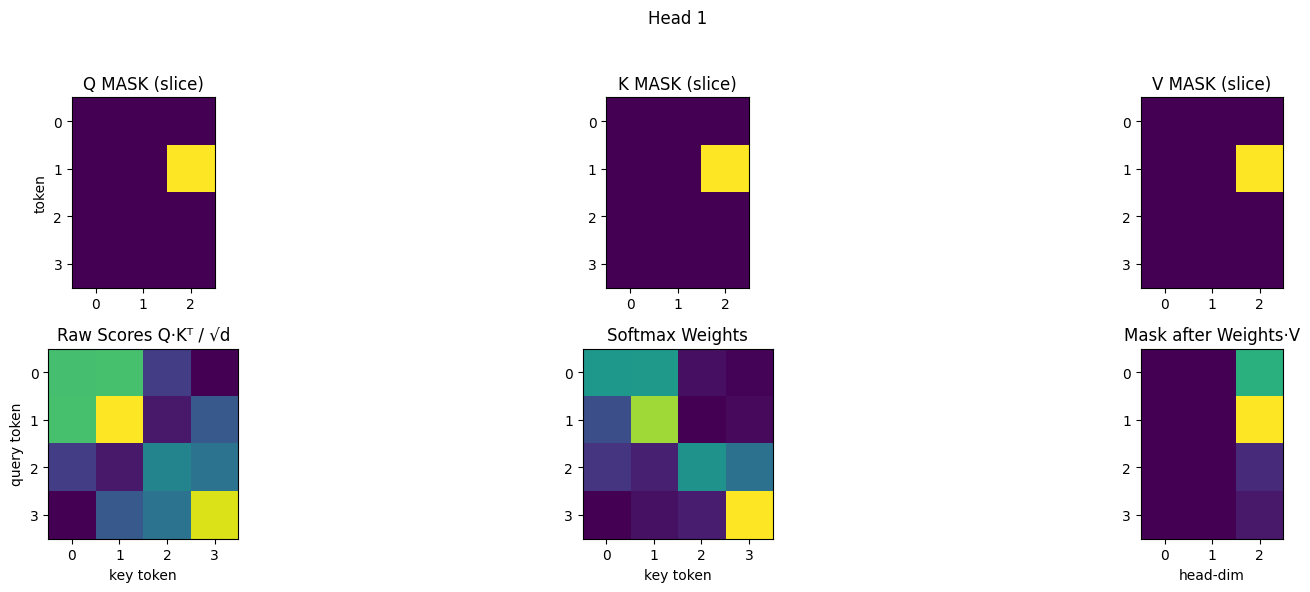

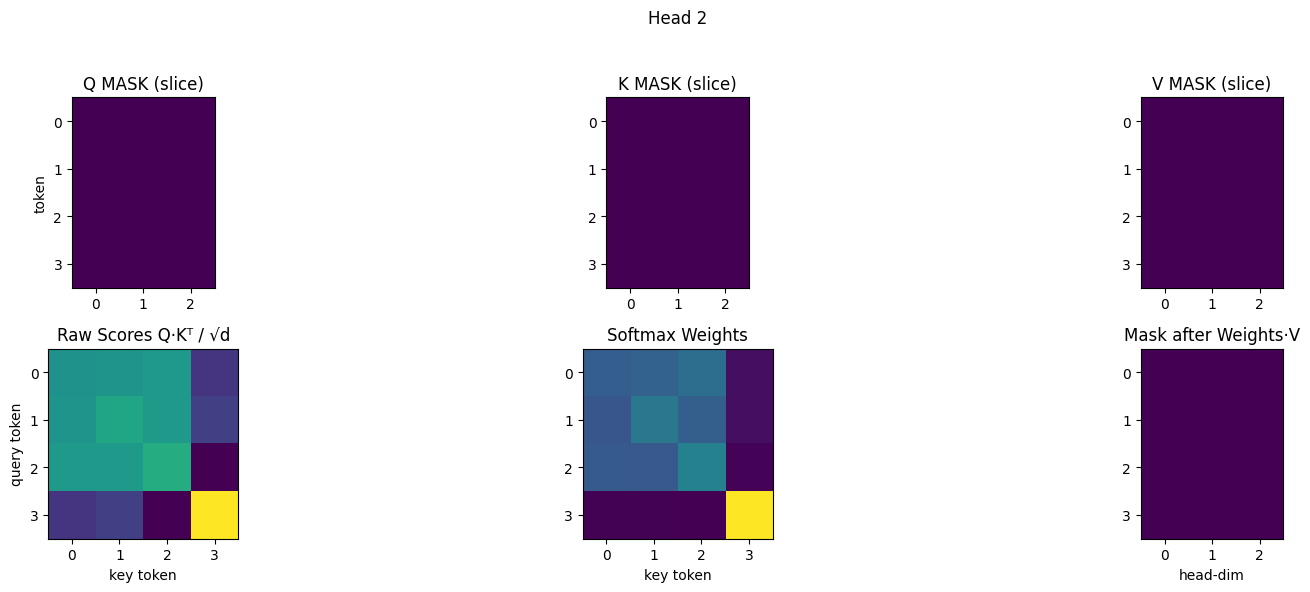

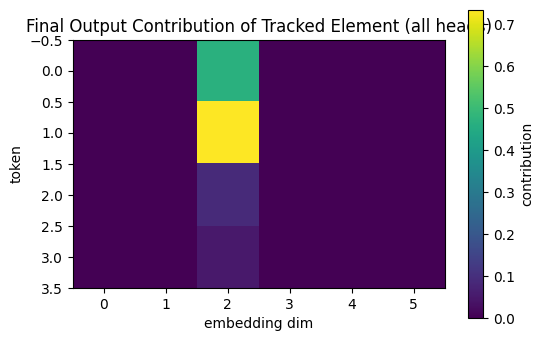

In [14]:
import torch, math, matplotlib.pyplot as plt, torch.nn.functional as F

# --- Config ------------------------------------------------------------------
seq_len   = 4        # tokens
embed_dim = 6        # model dimension
num_heads = 2
head_dim  = embed_dim // num_heads
track_tok = 1        # token row to follow
track_dim = 2        # embedding‑dim column to follow

torch.manual_seed(0)

# --- 1. Build toy input -------------------------------------------------------
values = torch.randn(seq_len, embed_dim)
print("Input VALUES:\n", values)

mask = torch.zeros_like(values)
mask[track_tok, track_dim] = 1.
print(f"\n>>> Tracking TOKEN {track_tok}, DIM {track_dim} (marked as 1 below)\n")
print(mask)

# --- 2. Deterministic slice projections --------------------------------------
W_q = torch.zeros(num_heads, embed_dim, head_dim)
for h in range(num_heads):
    W_q[h, h*head_dim:(h+1)*head_dim, :] = torch.eye(head_dim)
W_k = W_q.clone(); W_v = W_q.clone()

# --- 3. Produce Q/K/V for VALUES *and* MASK ----------------------------------
Q_val = torch.einsum('se,hed->shd', values, W_q)
K_val = torch.einsum('se,hed->shd', values, W_k)
V_val = torch.einsum('se,hed->shd', values, W_v)

Q_msk = torch.einsum('se,hed->shd', mask , W_q)
K_msk = torch.einsum('se,hed->shd', mask , W_k)
V_msk = torch.einsum('se,hed->shd', mask , W_v)

print("\nQ MASK (per head):\n", Q_msk)
print("K MASK (per head):\n", K_msk)
print("V MASK (per head):\n", V_msk)

# --- 4. Attention weights -----------------------------------------------------
scores  = torch.einsum('shd,thd->sht', Q_val, K_val) / math.sqrt(head_dim)  # (seq, head, seq)
scores  = scores.permute(1,0,2)                                            # (head, query, key)
print("\nRaw SCORES Head0:\n", scores[0])
weights = F.softmax(scores, dim=-1)
print("\nSoftmax WEIGHTS Head0:\n", weights[0])

# --- 5. Propagate mask through attention -------------------------------------
prop_msk_head = torch.einsum('hij,hjd->hid', weights, V_msk.permute(1,0,2))  # (head, seq, dim)
prop_msk      = prop_msk_head.permute(1,0,2).reshape(seq_len, embed_dim)

print("\nContribution of tracked element to OUTPUT (numbers):\n", prop_msk)

# --- 6. VISUALS --------------------------------------------------------------
for h in range(num_heads):
    fig, axs = plt.subplots(2, 3, figsize=(18,6))
    fig.suptitle(f"Head {h+1}")

    axs[0,0].imshow(Q_msk[:,h,:])
    axs[0,0].set_title("Q MASK (slice)")
    axs[0,0].set_ylabel("token")

    axs[0,1].imshow(K_msk[:,h,:])
    axs[0,1].set_title("K MASK (slice)")

    axs[0,2].imshow(V_msk[:,h,:])
    axs[0,2].set_title("V MASK (slice)")

    axs[1,0].imshow(scores[h].detach())
    axs[1,0].set_title("Raw Scores Q·Kᵀ / √d")
    axs[1,0].set_xlabel("key token"); axs[1,0].set_ylabel("query token")

    axs[1,1].imshow(weights[h].detach())
    axs[1,1].set_title("Softmax Weights")
    axs[1,1].set_xlabel("key token")

    axs[1,2].imshow(prop_msk_head[h])
    axs[1,2].set_title("Mask after Weights·V")
    axs[1,2].set_xlabel("head‑dim")

    plt.tight_layout(rect=[0,0,1,0.95]); plt.show()

plt.figure(figsize=(6,4))
plt.title("Final Output Contribution of Tracked Element (all heads)")
plt.imshow(prop_msk)
plt.xlabel("embedding dim"); plt.ylabel("token")
plt.colorbar(label='contribution'); plt.show()
